# EQCLib と CHIMES の遮蔽ありグリッド比較

現行 EQCLib の化学平衡モードを主系列とし、熱平衡、冷却率、等積冷却履歴、1セル更新の CPU 時間を CHIMES と比較します。EQCLib は H₂、ダスト遮蔽、ダスト熱過程、宇宙線、H–O 電荷交換、高温 CIE 冷却を有効にし、CO を無効にします。エネルギー更新の許容誤差は $10^{-4}$、化学平衡の許容誤差の上限は $10^{-5}$ です。CO を有効にした平衡計算と、非平衡モードは同じ現行版の対照です。

CHIMES `matched` は H・He・C・O・Si を扱い、`full` は N・Ne・Mg・S・Ca・Fe を Wiersma et al. (2009) の組成で加えます。EQCLib は追跡元素の数密度と Asplund et al. (2009) の組成による6元素の補完で高温 CIE 冷却を評価します。両コードに共通の遠紫外線強度・宇宙線・遮蔽を与え、軟 X 線と H の光電離を無効にします。CHIMES の `full-euv` は B87 の EUV 成分を含む対照です。

`test/out/chimes/shielded/` の CSV から図と集計表を描きます。別の計算結果を使う場合は最初のセルの `data_dir` を変更してください。 [初期条件と再計算手順](../test/chimes/shielded/README.md)

低温ガスの H₂ 分率と熱収支は、同じ元素組成とドップラー乱流幅を使った計算で詳しく比較します。 [低温ガスの比較](PlotH2Comparison.ipynb)

In [1]:
import sys
from pathlib import Path
from tempfile import TemporaryDirectory

from IPython.display import Image, Markdown, display

cwd = Path.cwd().resolve()
eqclib_dir = next(
    (directory for directory in (cwd, *cwd.parents, cwd / "EQCLib")
     if (directory / "src/ChemicalEquilibriumCooling.h").is_file()),
    None,
)
if eqclib_dir is None:
    raise FileNotFoundError("EQCLib のリポジトリ内でノートブックを実行してください。")

sys.path.insert(0, str(eqclib_dir / "plot"))
from plot_chimes_comparison import DEFAULT_DIR, generate_report

data_dir = DEFAULT_DIR
if not data_dir.is_dir():
    raise FileNotFoundError(f"比較 CSV がありません。README の手順で計算してください。{data_dir}")

plot_workspace = TemporaryDirectory(prefix="eqclib-chimes-shielded-")
plot_dir = Path(plot_workspace.name)
summary = generate_report(data_dir, plot_dir)


def show_plots(*filenames):
    for filename in filenames:
        display(Image(filename=str(plot_dir / filename), width=1200))

## 化学平衡と熱平衡

密度ごとの組成・加熱・冷却、CHIMES full に対する率の比、加熱と冷却が釣り合う温度を示します。

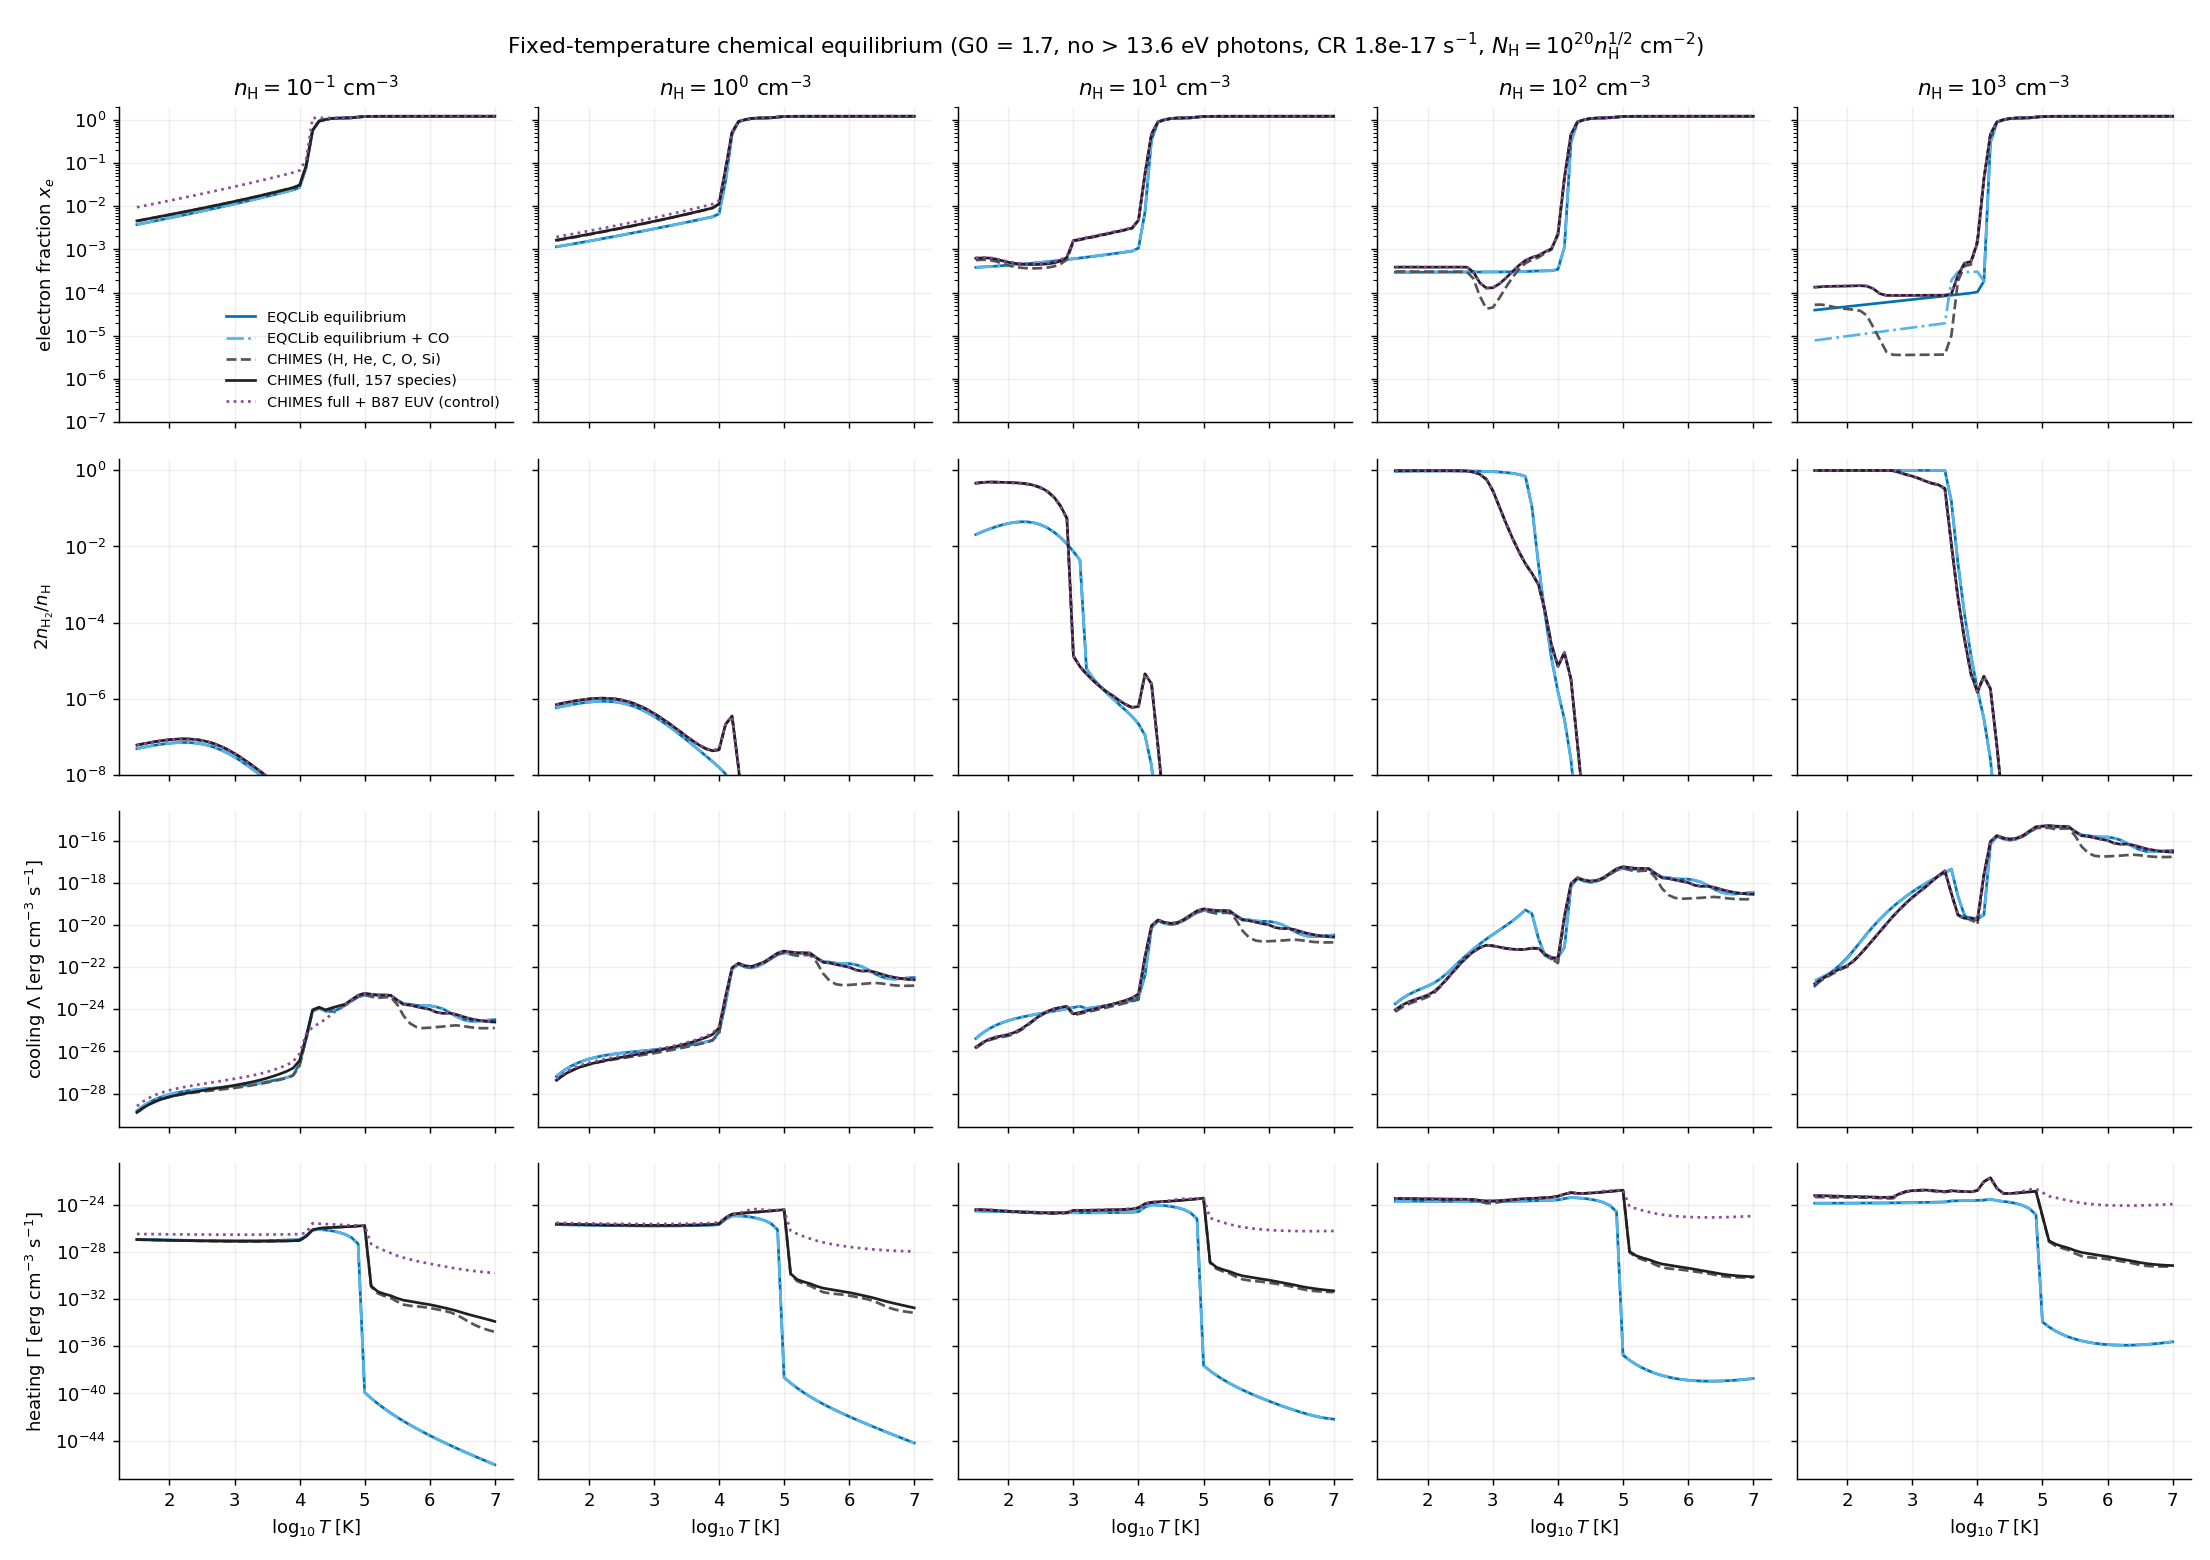

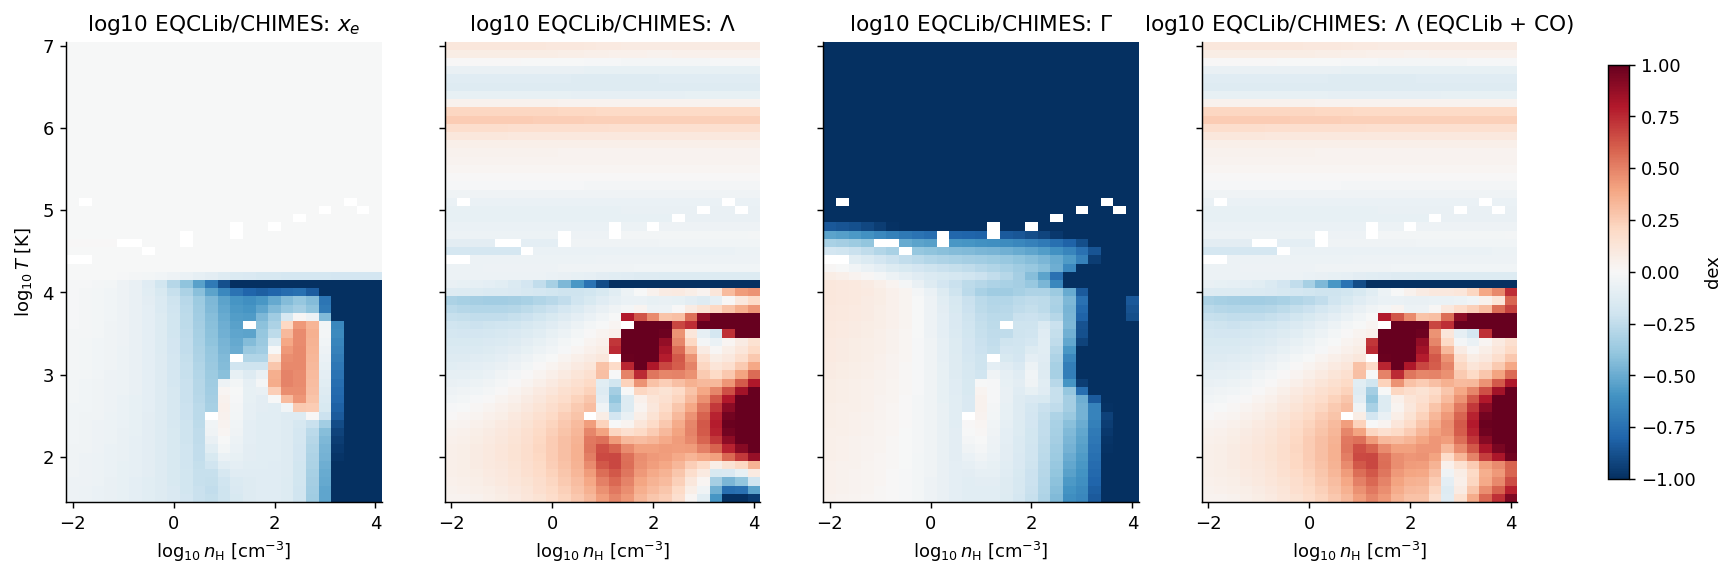

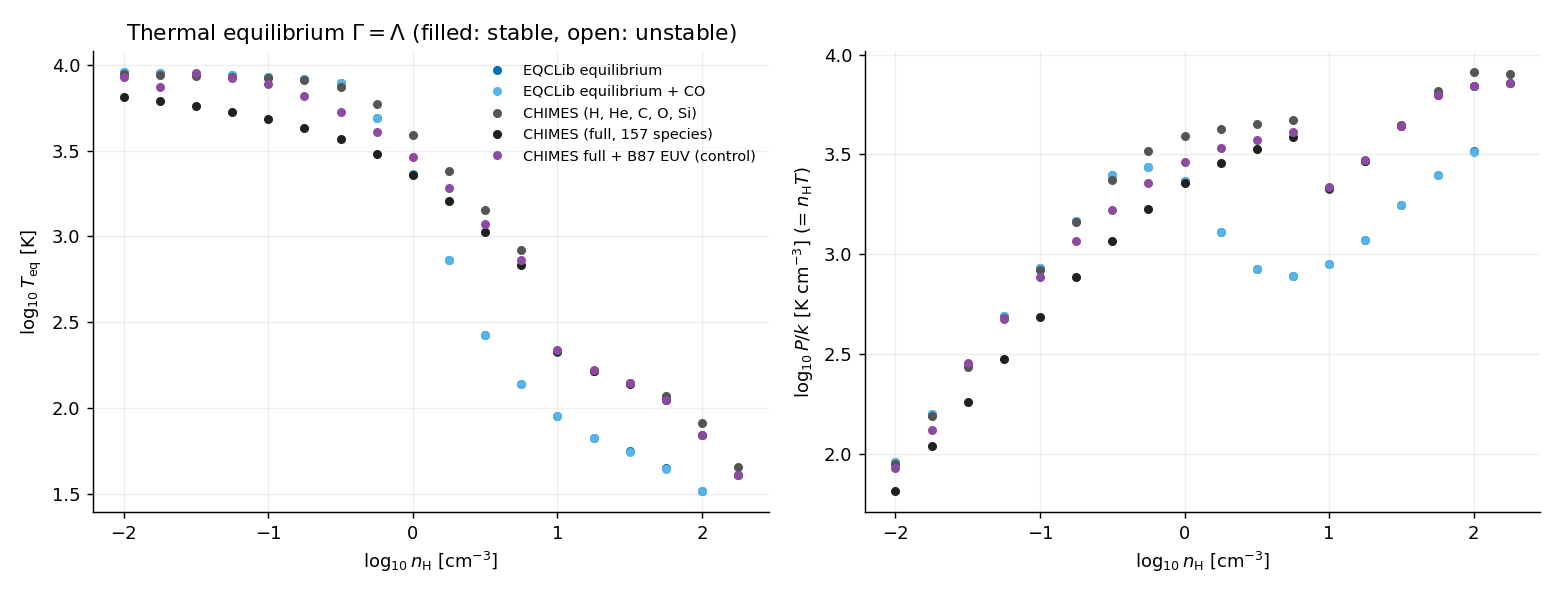

In [2]:
show_plots("equilibrium_profiles.png", "equilibrium_ratio_maps.png", "thermal_equilibrium.png")

## 1セル更新の計算時間と到達温度

10年・1万年・100万年刻みで、それぞれのコードの化学平衡状態から更新したときの CPU 時間と到達温度を示します。

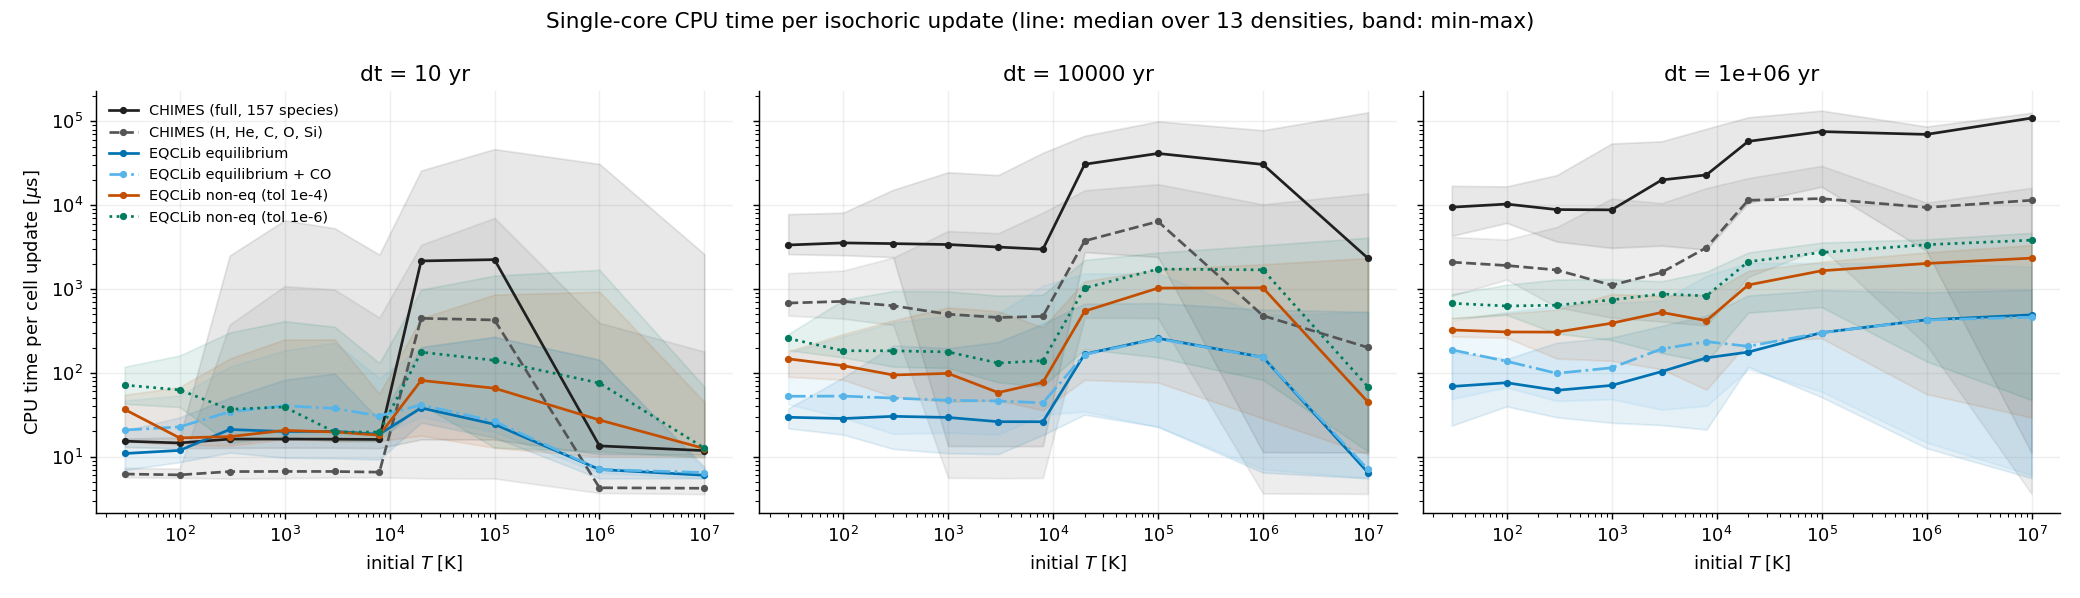

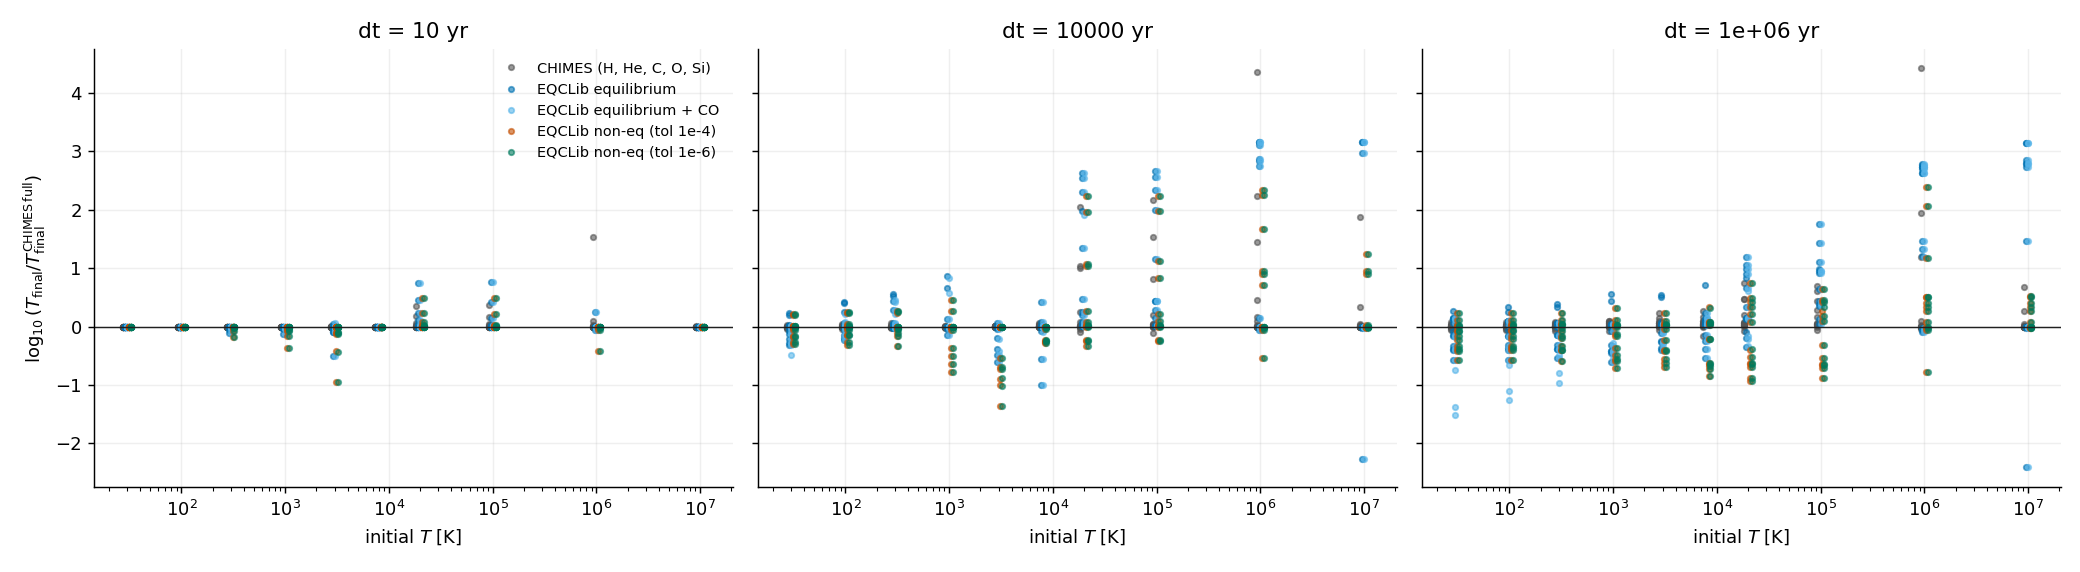

In [3]:
show_plots("timing.png", "timing_final_temperature.png")

## 銀河計算に近い時間刻みでの更新

粒子質量 10² と 10⁴ M☉ の SPH 粒子のクーラン条件 `dt = 0.3 h / c_s`（`h = (m/ρ)^{1/3}`、上限 1 Myr）で、各コードの化学平衡状態から1回更新したときの CPU 時間を示します。両コードには同じ時間刻みを与えます。同じ条件で成功した各モデルの到達温度の差を、最後の集計表に示します。

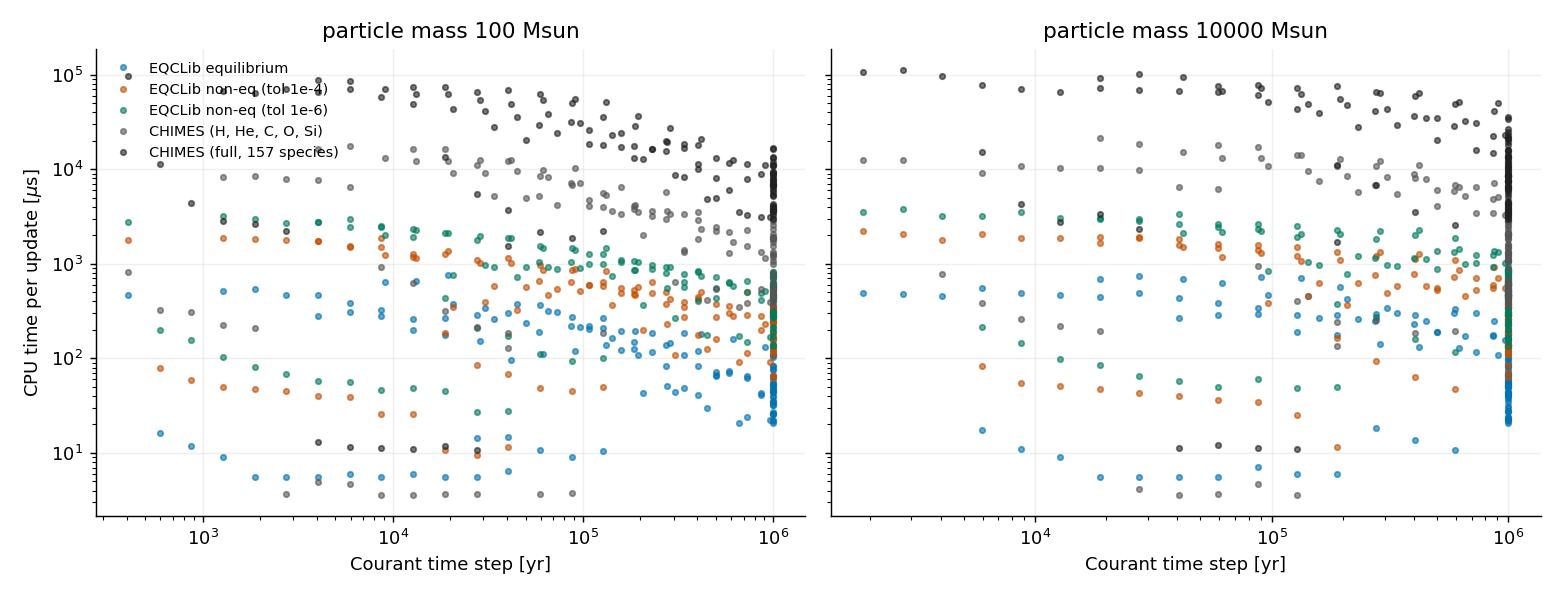

In [4]:
show_plots("courant_timing.png")

## 等積冷却履歴

初期温度と密度を変えた6ケースの時間発展を示します。

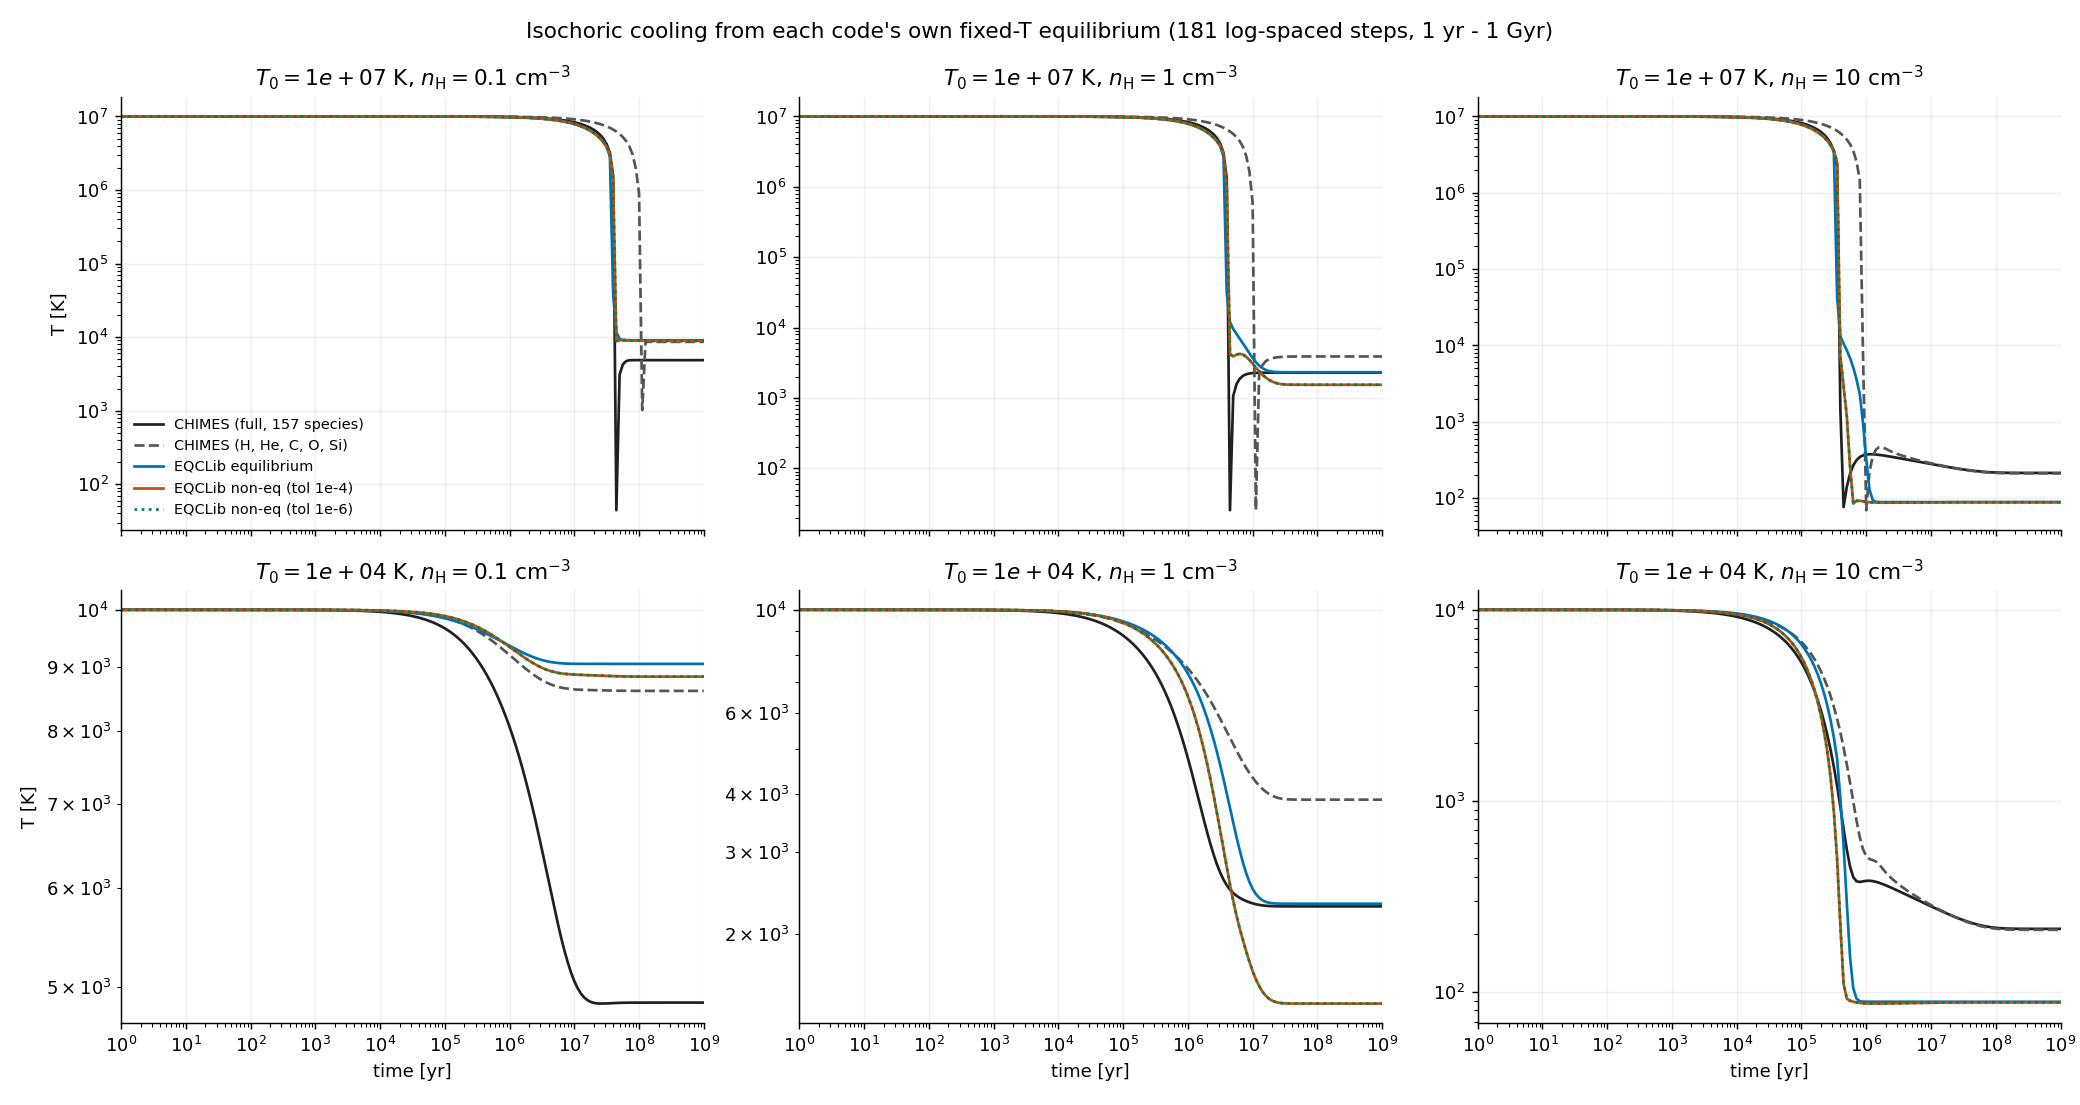

In [5]:
show_plots("cooling_histories.png")

## 集計表

収束数、平衡の一致度、成功セルの速度比、クーラン条件での計算時間と到達温度の差、冷却履歴の計測結果を表示します。

In [6]:
display(Markdown(summary))

With the current benchmark settings, EQCLib applies an Asplund et al. (2009) CIE supplement for N, Ne, Mg, S, Ca and Fe. CHIMES matched evolves H, He, C, O and Si. CHIMES full adds the six elements at Wiersma et al. (2009) abundances.

## Equilibrium

Converged: eqclib 1400/1400, eqclib_co 1400/1400, chimes_matched 1381/1400, chimes_full 1382/1400, chimes_full_euv 1354/1400

Median CPU per fixed-T equilibrium [us]: eqclib 22.0, eqclib_co 29.7, chimes_matched 3728.7, chimes_full 29515.6, chimes_full_euv 32101.3

| model | quantity | regime | N | median abs(log10 ratio) | within x2 |
| --- | --- | --- | ---: | ---: | ---: |
| eqclib | xe | T < 1e4 K | 622 | 0.16 | 66% |
| eqclib | xe | 1e4 <= T < 1e5 K | 239 | 0.00 | 87% |
| eqclib | xe | T >= 1e5 K | 521 | 0.00 | 100% |
| eqclib | fH2 | T < 1e4 K | 300 | 0.04 | 64% |
| eqclib | cool | T < 1e4 K | 622 | 0.20 | 64% |
| eqclib | cool | 1e4 <= T < 1e5 K | 239 | 0.06 | 92% |
| eqclib | cool | T >= 1e5 K | 521 | 0.07 | 100% |
| eqclib | heat | T < 1e4 K | 622 | 0.11 | 73% |
| eqclib | heat | 1e4 <= T < 1e5 K | 239 | 0.57 | 28% |
| eqclib | heat | T >= 1e5 K | 521 | 9.81 | 0% |
| eqclib_co | xe | T < 1e4 K | 622 | 0.16 | 66% |
| eqclib_co | xe | 1e4 <= T < 1e5 K | 239 | 0.00 | 87% |
| eqclib_co | xe | T >= 1e5 K | 521 | 0.00 | 100% |
| eqclib_co | fH2 | T < 1e4 K | 300 | 0.04 | 64% |
| eqclib_co | cool | T < 1e4 K | 622 | 0.20 | 63% |
| eqclib_co | cool | 1e4 <= T < 1e5 K | 239 | 0.06 | 92% |
| eqclib_co | cool | T >= 1e5 K | 521 | 0.07 | 100% |
| eqclib_co | heat | T < 1e4 K | 622 | 0.11 | 73% |
| eqclib_co | heat | 1e4 <= T < 1e5 K | 239 | 0.57 | 28% |
| eqclib_co | heat | T >= 1e5 K | 521 | 9.81 | 0% |
| chimes_matched | xe | T < 1e4 K | 622 | 0.02 | 77% |
| chimes_matched | xe | 1e4 <= T < 1e5 K | 238 | 0.00 | 100% |
| chimes_matched | xe | T >= 1e5 K | 521 | 0.00 | 100% |
| chimes_matched | fH2 | T < 1e4 K | 283 | 0.00 | 100% |
| chimes_matched | cool | T < 1e4 K | 622 | 0.03 | 98% |
| chimes_matched | cool | 1e4 <= T < 1e5 K | 238 | 0.04 | 100% |
| chimes_matched | cool | T >= 1e5 K | 521 | 0.39 | 38% |
| chimes_matched | heat | T < 1e4 K | 622 | 0.01 | 99% |
| chimes_matched | heat | 1e4 <= T < 1e5 K | 238 | 0.00 | 100% |
| chimes_matched | heat | T >= 1e5 K | 521 | 0.22 | 78% |
| chimes_full_euv | xe | T < 1e4 K | 595 | 0.02 | 79% |
| chimes_full_euv | xe | 1e4 <= T < 1e5 K | 232 | 0.00 | 97% |
| chimes_full_euv | xe | T >= 1e5 K | 521 | 0.00 | 100% |
| chimes_full_euv | fH2 | T < 1e4 K | 258 | 0.00 | 100% |
| chimes_full_euv | cool | T < 1e4 K | 595 | 0.01 | 80% |
| chimes_full_euv | cool | 1e4 <= T < 1e5 K | 232 | 0.00 | 90% |
| chimes_full_euv | cool | T >= 1e5 K | 521 | 0.00 | 100% |
| chimes_full_euv | heat | T < 1e4 K | 595 | 0.03 | 75% |
| chimes_full_euv | heat | 1e4 <= T < 1e5 K | 232 | 0.05 | 84% |
| chimes_full_euv | heat | T >= 1e5 K | 521 | 4.09 | 4% |

## Timing

| method | dt [yr] | success | median us | p90 us | mean us | Chimes-full / method (median of per-cell ratios) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| chimes_full | 10 | 129/130 | 16.1 | 3653.1 | 2139.2 | 1.0 |
| chimes_full | 10000 | 129/130 | 3835.3 | 61839.0 | 17758.0 | 1.0 |
| chimes_full | 1e+06 | 129/130 | 20017.4 | 82791.6 | 34899.0 | 1.0 |
| chimes_matched | 10 | 129/130 | 6.6 | 516.2 | 285.5 | 2.7 |
| chimes_matched | 10000 | 129/130 | 677.8 | 9829.6 | 2690.1 | 5.6 |
| chimes_matched | 1e+06 | 129/130 | 3092.5 | 13830.4 | 5586.4 | 5.7 |
| eqclib_eq | 10 | 130/130 | 18.1 | 67.2 | 30.3 | 1.4 |
| eqclib_eq | 10000 | 130/130 | 36.1 | 381.2 | 124.4 | 117.9 |
| eqclib_eq | 1e+06 | 130/130 | 128.1 | 624.8 | 237.9 | 152.3 |
| eqclib_co_eq | 10 | 130/130 | 29.1 | 118.5 | 44.2 | 0.8 |
| eqclib_co_eq | 10000 | 130/130 | 67.3 | 471.2 | 195.4 | 64.8 |
| eqclib_co_eq | 1e+06 | 130/130 | 210.0 | 1249.3 | 412.2 | 80.1 |
| eqclib_noneq_1e-4 | 10 | 130/130 | 27.2 | 176.9 | 75.6 | 1.0 |
| eqclib_noneq_1e-4 | 10000 | 130/130 | 143.5 | 1240.2 | 400.3 | 34.7 |
| eqclib_noneq_1e-4 | 1e+06 | 130/130 | 484.0 | 2111.6 | 792.0 | 41.0 |
| eqclib_noneq_1e-6 | 10 | 130/130 | 67.7 | 306.9 | 143.1 | 0.8 |
| eqclib_noneq_1e-6 | 10000 | 130/130 | 268.1 | 2228.4 | 711.5 | 19.3 |
| eqclib_noneq_1e-6 | 1e+06 | 130/130 | 853.4 | 3548.9 | 1336.6 | 22.5 |

CHIMES CPU time / EQCLib CPU time (>1: EQCLib faster). 'sum' = ratio of summed times, 'median' = median of per-cell ratios.

| CHIMES | EQCLib | dt=10 yr sum / median | dt=10000 yr sum / median | dt=1e+06 yr sum / median |
| --- | --- | ---: | ---: | ---: |
| chimes_matched | eqclib_eq | 9.5 / 0.60 | 21.8 / 19.01 | 24.0 / 22.99 |
| chimes_matched | eqclib_co_eq | 6.5 / 0.34 | 13.8 / 10.93 | 13.9 / 13.30 |
| chimes_matched | eqclib_noneq_1e-4 | 3.9 / 0.37 | 6.9 / 5.34 | 7.1 / 6.17 |
| chimes_matched | eqclib_noneq_1e-6 | 2.1 / 0.31 | 3.9 / 2.87 | 4.2 / 3.13 |
| chimes_full | eqclib_eq | 71.4 / 1.44 | 143.7 / 117.92 | 150.0 / 152.32 |
| chimes_full | eqclib_co_eq | 48.6 / 0.82 | 91.1 / 64.77 | 87.0 / 80.14 |
| chimes_full | eqclib_noneq_1e-4 | 29.1 / 0.99 | 45.5 / 34.66 | 44.6 / 41.00 |
| chimes_full | eqclib_noneq_1e-6 | 15.5 / 0.82 | 25.5 / 19.29 | 26.4 / 22.53 |

## Courant-step updates

### Particle mass 100 Msun

129 cells; Courant dt median 2.32e+05 yr, range 405-1e+06 yr, 28% at the 1 Myr cap.

| method | median us | mean us | p90 us | CPU s per 1e6 updates | CHIMES full / method (sum) |
| --- | ---: | ---: | ---: | ---: | ---: |
| eqclib_eq | 82.7 | 140.5 | 328.5 | 141 | 156.4 |
| eqclib_noneq_1e-4 | 330.4 | 478.6 | 1182.6 | 479 | 45.9 |
| eqclib_noneq_1e-6 | 641.6 | 851.6 | 2055.7 | 852 | 25.8 |
| chimes_matched | 2050.8 | 3660.2 | 9644.1 | 3660 | 6.0 |
| chimes_full | 11573.8 | 21978.8 | 62475.8 | 21979 | 1.0 |

abs(log10) difference of the final temperature after one Courant step (median dex / fraction within a factor 2):

| comparison | all | T0 < 8e3 K | 8e3 <= T0 < 3e4 K | T0 >= 1e5 K |
| --- | ---: | ---: | ---: | ---: |
| EQCLib eq vs non-eq (tol 1e-6) | 0.10 / 67% | 0.05 / 83% | 0.31 / 50% | 0.19 / 53% |
| EQCLib non-eq (tol 1e-6) vs CHIMES matched | 0.19 / 65% | 0.24 / 58% | 0.24 / 62% | 0.04 / 79% |
| CHIMES matched vs CHIMES full | 0.03 / 88% | 0.02 / 100% | 0.06 / 85% | 0.07 / 71% |
| EQCLib eq vs CHIMES full | 0.17 / 59% | 0.16 / 65% | 0.24 / 58% | 0.33 / 50% |
| EQCLib non-eq tolerance 1e-4 vs 1e-6 | 0.00 / 100% | 0.00 / 100% | 0.00 / 100% | 0.00 / 100% |

### Particle mass 10000 Msun

129 cells; Courant dt median 1e+06 yr, range 1.88e+03-1e+06 yr, 50% at the 1 Myr cap.

| method | median us | mean us | p90 us | CPU s per 1e6 updates | CHIMES full / method (sum) |
| --- | ---: | ---: | ---: | ---: | ---: |
| eqclib_eq | 109.5 | 178.7 | 466.9 | 179 | 155.0 |
| eqclib_noneq_1e-4 | 391.6 | 602.3 | 1530.6 | 602 | 46.0 |
| eqclib_noneq_1e-6 | 806.4 | 1058.8 | 2522.1 | 1059 | 26.2 |
| chimes_matched | 2519.6 | 4437.9 | 11253.1 | 4438 | 6.2 |
| chimes_full | 14507.1 | 27711.3 | 71340.2 | 27711 | 1.0 |

abs(log10) difference of the final temperature after one Courant step (median dex / fraction within a factor 2):

| comparison | all | T0 < 8e3 K | 8e3 <= T0 < 3e4 K | T0 >= 1e5 K |
| --- | ---: | ---: | ---: | ---: |
| EQCLib eq vs non-eq (tol 1e-6) | 0.10 / 67% | 0.05 / 91% | 0.39 / 46% | 0.46 / 39% |
| EQCLib non-eq (tol 1e-6) vs CHIMES matched | 0.19 / 62% | 0.22 / 62% | 0.20 / 58% | 0.12 / 66% |
| CHIMES matched vs CHIMES full | 0.03 / 88% | 0.02 / 100% | 0.05 / 88% | 0.04 / 68% |
| EQCLib eq vs CHIMES full | 0.17 / 56% | 0.15 / 62% | 0.15 / 69% | 0.90 / 37% |
| EQCLib non-eq tolerance 1e-4 vs 1e-6 | 0.00 / 100% | 0.00 / 100% | 0.00 / 100% | 0.00 / 100% |

## Cooling histories

| T0 | nH | method | total CPU ms | steps | failures |
| ---: | ---: | --- | ---: | ---: | ---: |
| 1e+07 | 0.1 | chimes_full | 273.1 | 181 | 0 |
| 1e+07 | 0.1 | chimes_matched | 28.7 | 181 | 0 |
| 1e+07 | 0.1 | eqclib_eq | 2.1 | 181 | 0 |
| 1e+07 | 0.1 | eqclib_noneq_1e-4 | 7.6 | 181 | 0 |
| 1e+07 | 0.1 | eqclib_noneq_1e-6 | 11.8 | 181 | 0 |
| 1e+07 | 1 | chimes_full | 306.5 | 181 | 0 |
| 1e+07 | 1 | chimes_matched | 37.5 | 181 | 0 |
| 1e+07 | 1 | eqclib_eq | 8.6 | 181 | 0 |
| 1e+07 | 1 | eqclib_noneq_1e-4 | 10.4 | 181 | 0 |
| 1e+07 | 1 | eqclib_noneq_1e-6 | 16.5 | 181 | 0 |
| 1e+07 | 10 | chimes_full | 448.5 | 181 | 0 |
| 1e+07 | 10 | chimes_matched | 60.4 | 181 | 0 |
| 1e+07 | 10 | eqclib_eq | 2.3 | 181 | 0 |
| 1e+07 | 10 | eqclib_noneq_1e-4 | 11.9 | 181 | 0 |
| 1e+07 | 10 | eqclib_noneq_1e-6 | 19.1 | 181 | 0 |
| 1e+04 | 0.1 | chimes_full | 234.9 | 181 | 0 |
| 1e+04 | 0.1 | chimes_matched | 36.0 | 181 | 0 |
| 1e+04 | 0.1 | eqclib_eq | 4.4 | 181 | 0 |
| 1e+04 | 0.1 | eqclib_noneq_1e-4 | 8.6 | 181 | 0 |
| 1e+04 | 0.1 | eqclib_noneq_1e-6 | 13.4 | 181 | 0 |
| 1e+04 | 1 | chimes_full | 280.6 | 181 | 0 |
| 1e+04 | 1 | chimes_matched | 45.5 | 181 | 0 |
| 1e+04 | 1 | eqclib_eq | 18.3 | 181 | 0 |
| 1e+04 | 1 | eqclib_noneq_1e-4 | 7.8 | 181 | 0 |
| 1e+04 | 1 | eqclib_noneq_1e-6 | 14.2 | 181 | 0 |
| 1e+04 | 10 | chimes_full | 444.0 | 181 | 0 |
| 1e+04 | 10 | chimes_matched | 66.0 | 181 | 0 |
| 1e+04 | 10 | eqclib_eq | 3.6 | 181 | 0 |
| 1e+04 | 10 | eqclib_noneq_1e-4 | 10.1 | 181 | 0 |
| 1e+04 | 10 | eqclib_noneq_1e-6 | 17.6 | 181 | 0 |